# Интерпретация моделей стоимости недвижимости

**Проект:** House Prices AI — исследование исторических продаж недвижимости в Эймсе (США).

**Цель:** объяснить, какие характеристики используются алгоритмами прогнозирования цены и принадлежности к ценовому сегменту, сравнить глобальную важность признаков в Random Forest и XGBoost и исследовать локальные SHAP-вклады.

Признаки описывают наблюдаемые свойства домов, поэтому «важность» и «вклад в прогноз» **не являются доказательством причинного влияния на рыночную цену**.

На этом этапе используются ранее обученные XGBoost, а Random Forest обучается на тех же тренировочных объектах исключительно для сравнения. Внешняя тестовая часть применяется для **описательной интерпретации** прогнозов, но не для подбора гиперпараметров.

## 1. Методика и подготовка результатов

**Feature Importance (важность признаков)** показывает, насколько активно модель использует характеристику при обучении. В Random Forest применяется уменьшение неоднородности, а XGBoost по умолчанию предоставляет нормированную важность на основе выигрыша разделений (`gain`). Числа между алгоритмами нельзя непосредственно считать одной и той же физической величиной.

**SHAP (аддитивные объяснения по значениям Шепли)** представляет отдельный прогноз как сумму базового значения и вкладов характеристик. Для цены вклады измеряются в долларах США, для классификации XGBoost — на шкале *log-odds* (логарифма отношения шансов). Для получения вероятности применяется логистическая функция.

Ни один вывод не строится на будущем целевом значении как на входном признаке. В рамках описательного анализа уже изученная внешняя тестовая выборка не рассматривается как новая независимая оценка качества.

In [1]:
from pathlib import Path
import json
import os
import webbrowser
import pandas as pd
from IPython.display import Image, display

try:
    import ipywidgets as widgets
except ImportError:
    widgets = None

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RESULTS = ROOT / "outputs" / "explainability"
required = ["importance_regression_xgboost.csv", "importance_classification_xgboost.csv",
            "shap_global_regression.csv", "shap_global_classification.csv",
            "local_regression.json", "local_classification.json"]
missing = [name for name in required if not (RESULTS / name).is_file()]
if missing:
    raise FileNotFoundError(f"Не найдены результаты {missing}. Сначала выполните python -m house_prices_ai.explainability")

local_reg = json.loads((RESULTS / "local_regression.json").read_text(encoding="utf-8"))
local_clf = json.loads((RESULTS / "local_classification.json").read_text(encoding="utf-8"))
print("Дом для локальной регрессии:", local_reg["Id"])
print("Дом для локальной классификации:", local_clf["Id"])


def open_force_plot(filename: str) -> None:
    """Открыть локальный SHAP HTML в браузере по умолчанию.

    Работает на компьютере, на котором запущено ядро Python (Jupyter kernel).
    """
    path = (RESULTS / filename).resolve()
    if not path.is_file():
        raise FileNotFoundError(f"HTML Force Plot не найден: {path}")
    if path.suffix.lower() != ".html":
        raise ValueError("Ожидается HTML-файл Force Plot")

    launched = webbrowser.open_new_tab(path.as_uri())
    if not launched and os.name == "nt":
        # Запасной вариант Windows: открытие по назначенному приложению .html.
        os.startfile(str(path))
        launched = True
    if not launched:
        raise RuntimeError(
            "Не удалось открыть браузер. Откройте файл напрямую: " + str(path)
        )


def show_force_plot_button(filename: str, title: str) -> None:
    """Кнопка с запуском по нажатию, без открытия вкладок при Run All."""
    if widgets is None:
        print("Для кнопки установите ipywidgets: python -m pip install ipywidgets")
        print(f"Без кнопки выполните в отдельной ячейке: open_force_plot({filename!r})")
        return

    button = widgets.Button(
        description=title,
        icon="external-link",
        tooltip="Открыть локальный SHAP HTML в браузере по умолчанию",
        layout=widgets.Layout(width="auto"),
    )
    status = widgets.Output()

    def _on_click(_):
        with status:
            status.clear_output(wait=True)
            try:
                open_force_plot(filename)
            except Exception as exc:
                print(f"Ошибка открытия Force Plot: {exc}")

    button.on_click(_on_click)
    display(widgets.VBox([button, status]))

Дом для локальной регрессии: 1424
Дом для локальной классификации: 1051


## 2. Сопоставление встроенной важности: регрессия

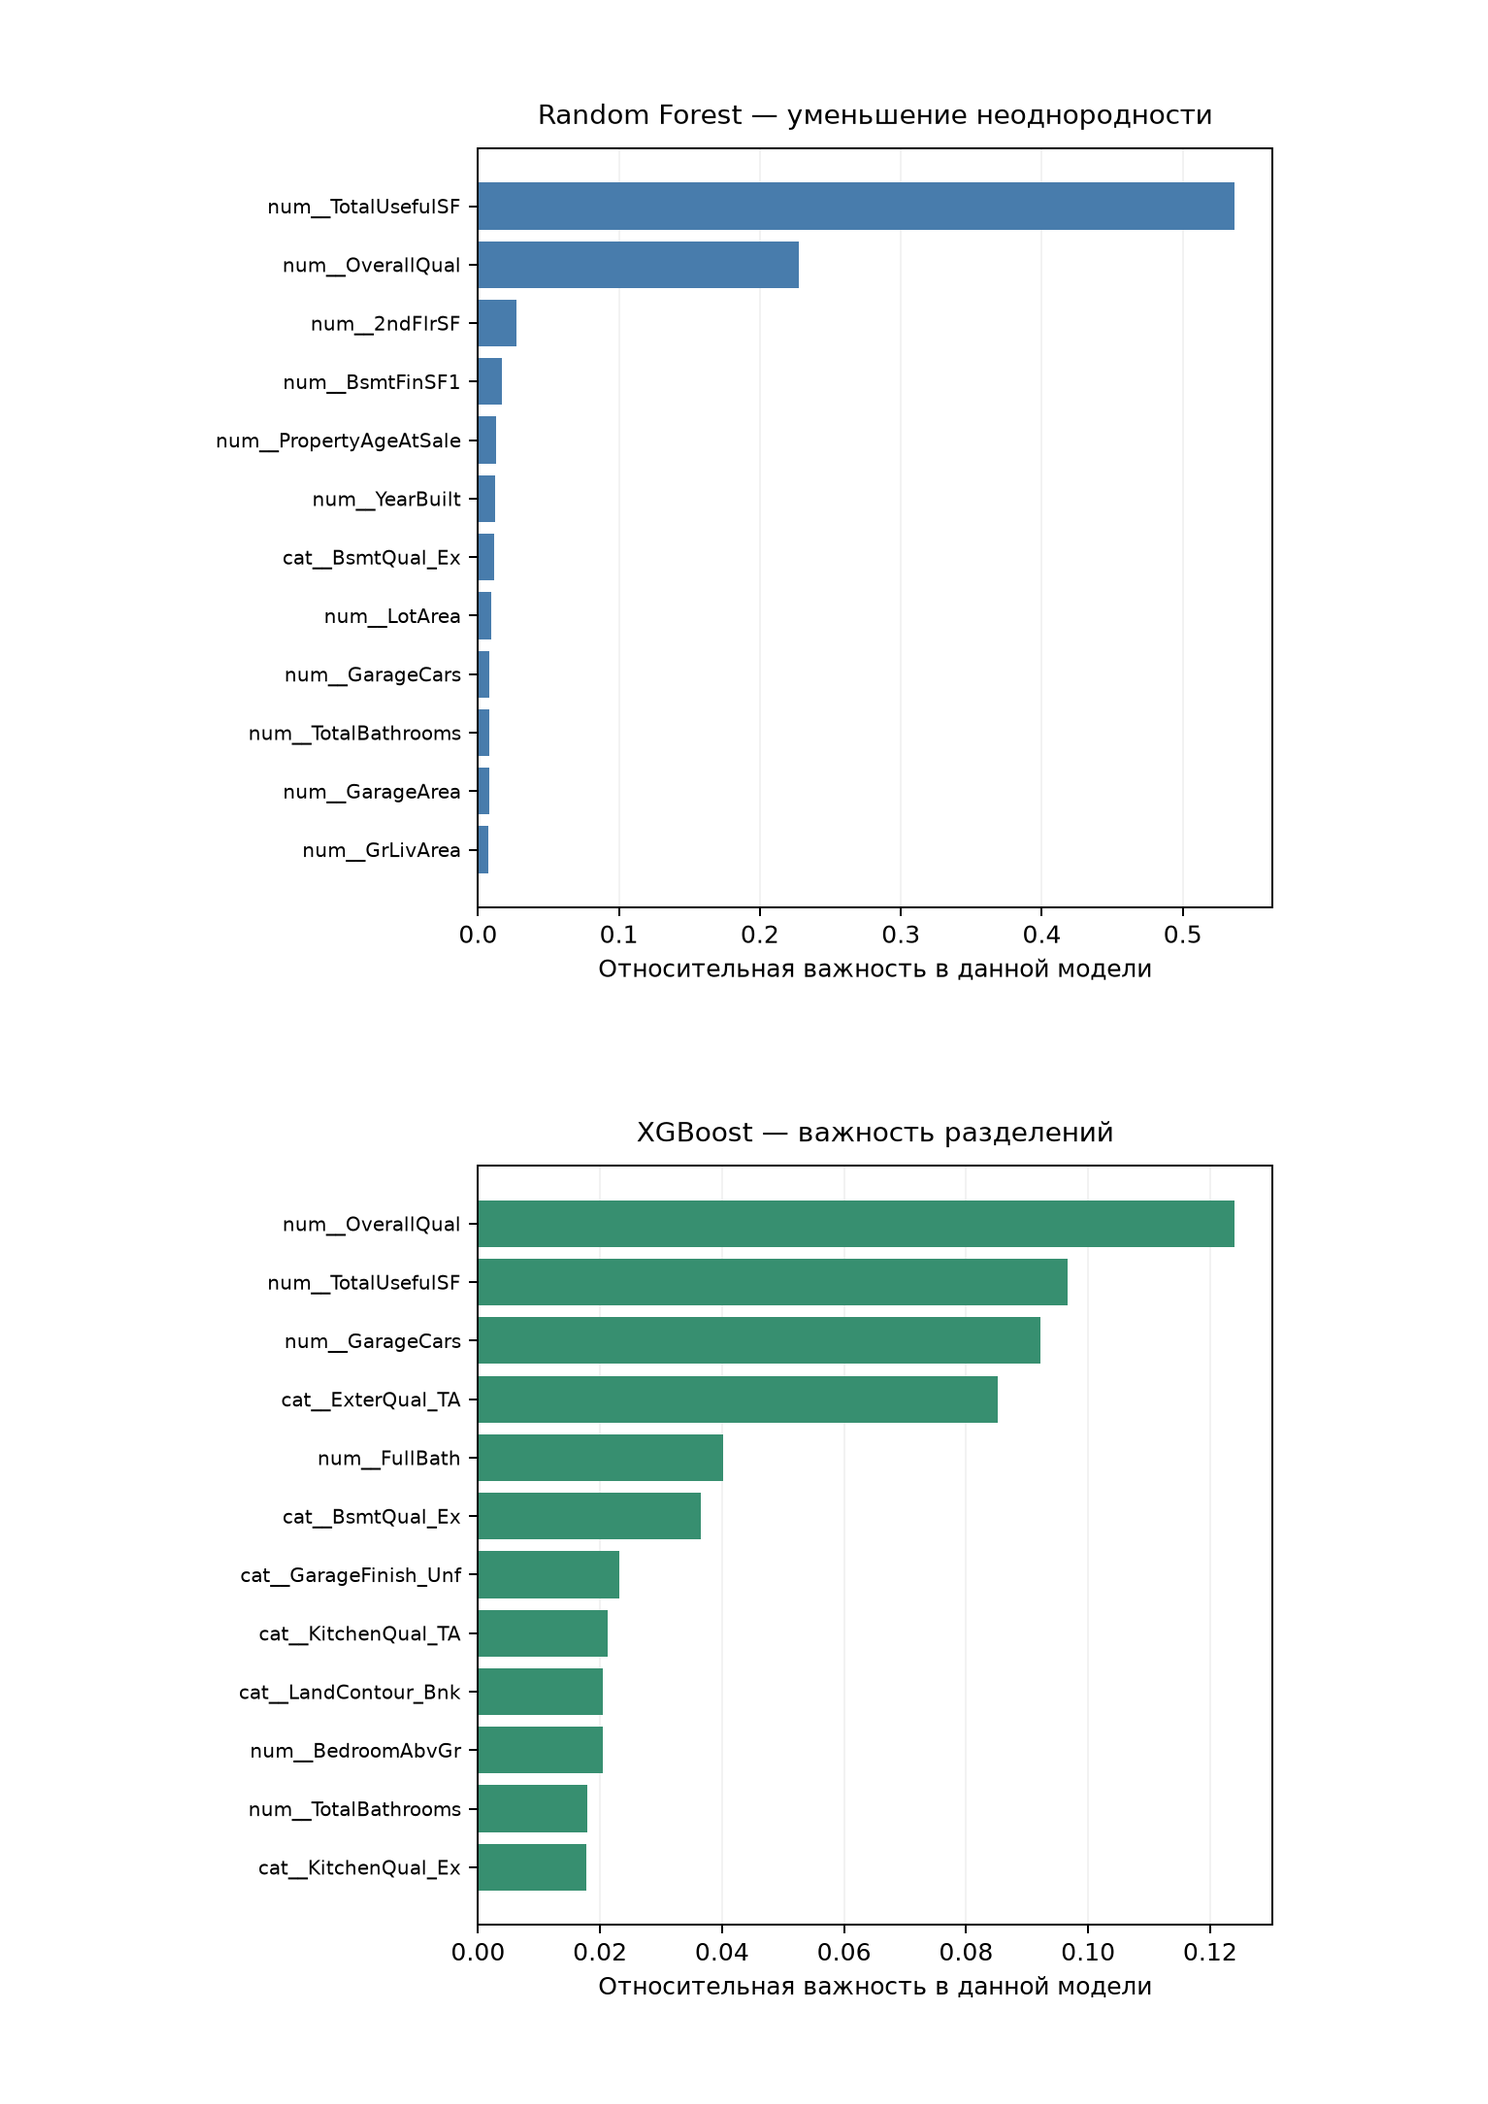

In [2]:
display(Image(filename=str(RESULTS / "figures" / "5_1_importance_regression.png")))

*Рисунок 5.1 — Относительная важность характеристик для Random Forest и XGBoost в прогнозировании стоимости.*

На рисунке сравниваются первые 12 признаков для двух ансамблевых алгоритмов. Важно различать ранжирование внутри каждой модели и относительный масштаб показателя. Если один и тот же признак находится высоко в обоих списках, он активно используется обеими моделями, но это не говорит о независимом причинном эффекте. Сильные корреляции могут перераспределять важность между связанными характеристиками.

In [3]:
rf_r = pd.read_csv(RESULTS / "importance_regression_random_forest.csv")
xgb_r = pd.read_csv(RESULTS / "importance_regression_xgboost.csv")
print("Random Forest — ведущие признаки")
display(rf_r.head(8))
print("XGBoost — ведущие признаки")
display(xgb_r.head(8))

Random Forest — ведущие признаки


,Feature,Importance
0,num__TotalUsefulSF,0.536748
1,num__OverallQual,0.227881
2,num__2ndFlrSF,0.027350
3,num__BsmtFinSF1,0.016833
4,num__PropertyAgeAtSale,0.012806
5,num__YearBuilt,0.011829
6,cat__BsmtQual_Ex,0.011375
7,num__LotArea,0.009042


XGBoost — ведущие признаки


,Feature,Importance
0,num__OverallQual,0.124006
1,num__TotalUsefulSF,0.096602
2,num__GarageCars,0.092152
3,cat__ExterQual_TA,0.085130
4,num__FullBath,0.040169
5,cat__BsmtQual_Ex,0.036448
6,cat__GarageFinish_Unf,0.023093
7,cat__KitchenQual_TA,0.021214


## 3. Сопоставление встроенной важности: классификация

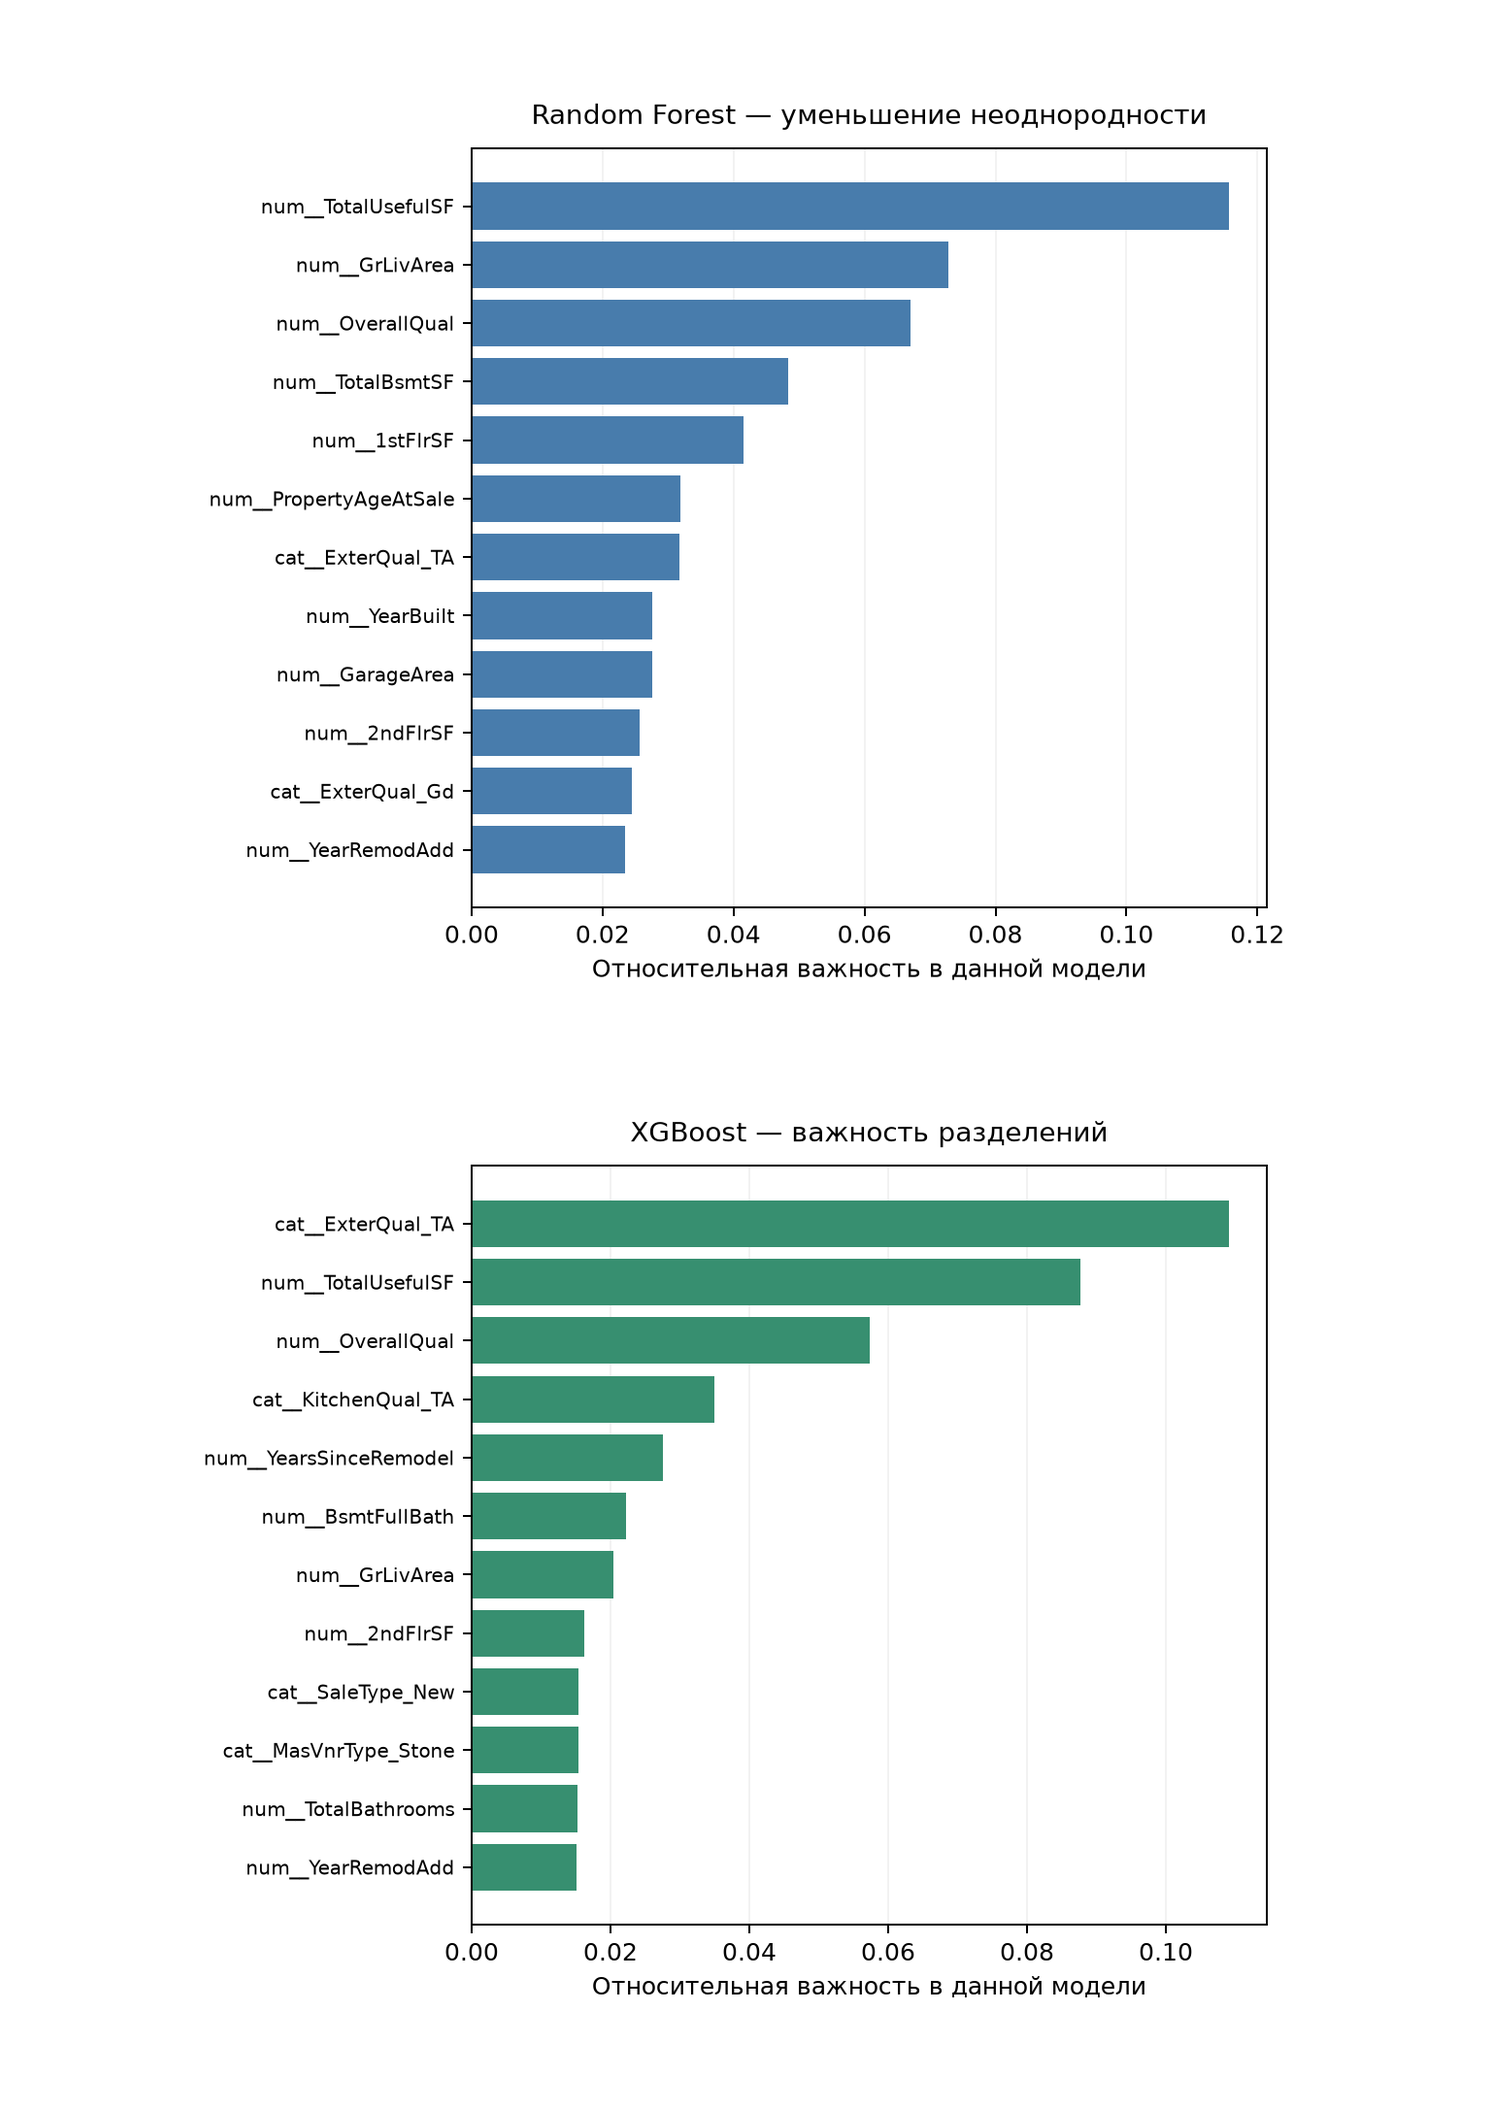

In [4]:
display(Image(filename=str(RESULTS / "figures" / "5_2_importance_classification.png")))

*Рисунок 5.2 — Относительная важность характеристик для Random Forest и XGBoost в определении ценового сегмента.*

Для бинарной классификации модель определяет, относится ли дом к сегменту стоимости от $200 000. Рейтинг признаков может отличаться от регрессионного, поскольку алгоритмы решают различные задачи. Сравнение с регрессией показывает, какие характеристики полезны для оценки точной цены, а какие — для отделения дорогого сегмента.

In [5]:
rf_c = pd.read_csv(RESULTS / "importance_classification_random_forest.csv")
xgb_c = pd.read_csv(RESULTS / "importance_classification_xgboost.csv")
display(xgb_c.head(10))

,Feature,Importance
0,cat__ExterQual_TA,0.109041
1,num__TotalUsefulSF,0.087710
2,num__OverallQual,0.057311
3,cat__KitchenQual_TA,0.034986
4,num__YearsSinceRemodel,0.027614
5,num__BsmtFullBath,0.022271
6,num__GrLivArea,0.020357
7,num__2ndFlrSF,0.016242
8,cat__SaleType_New,0.015412
9,cat__MasVnrType_Stone,0.015372


Совокупно рисунки 5.1 и 5.2 характеризуют глобальное использование признаков, но не показывают, повышает или понижает отдельная характеристика прогноз конкретного дома. Для изучения направления и величины модельного вклада далее используется SHAP.

## 4. Глобальный SHAP-анализ стоимости

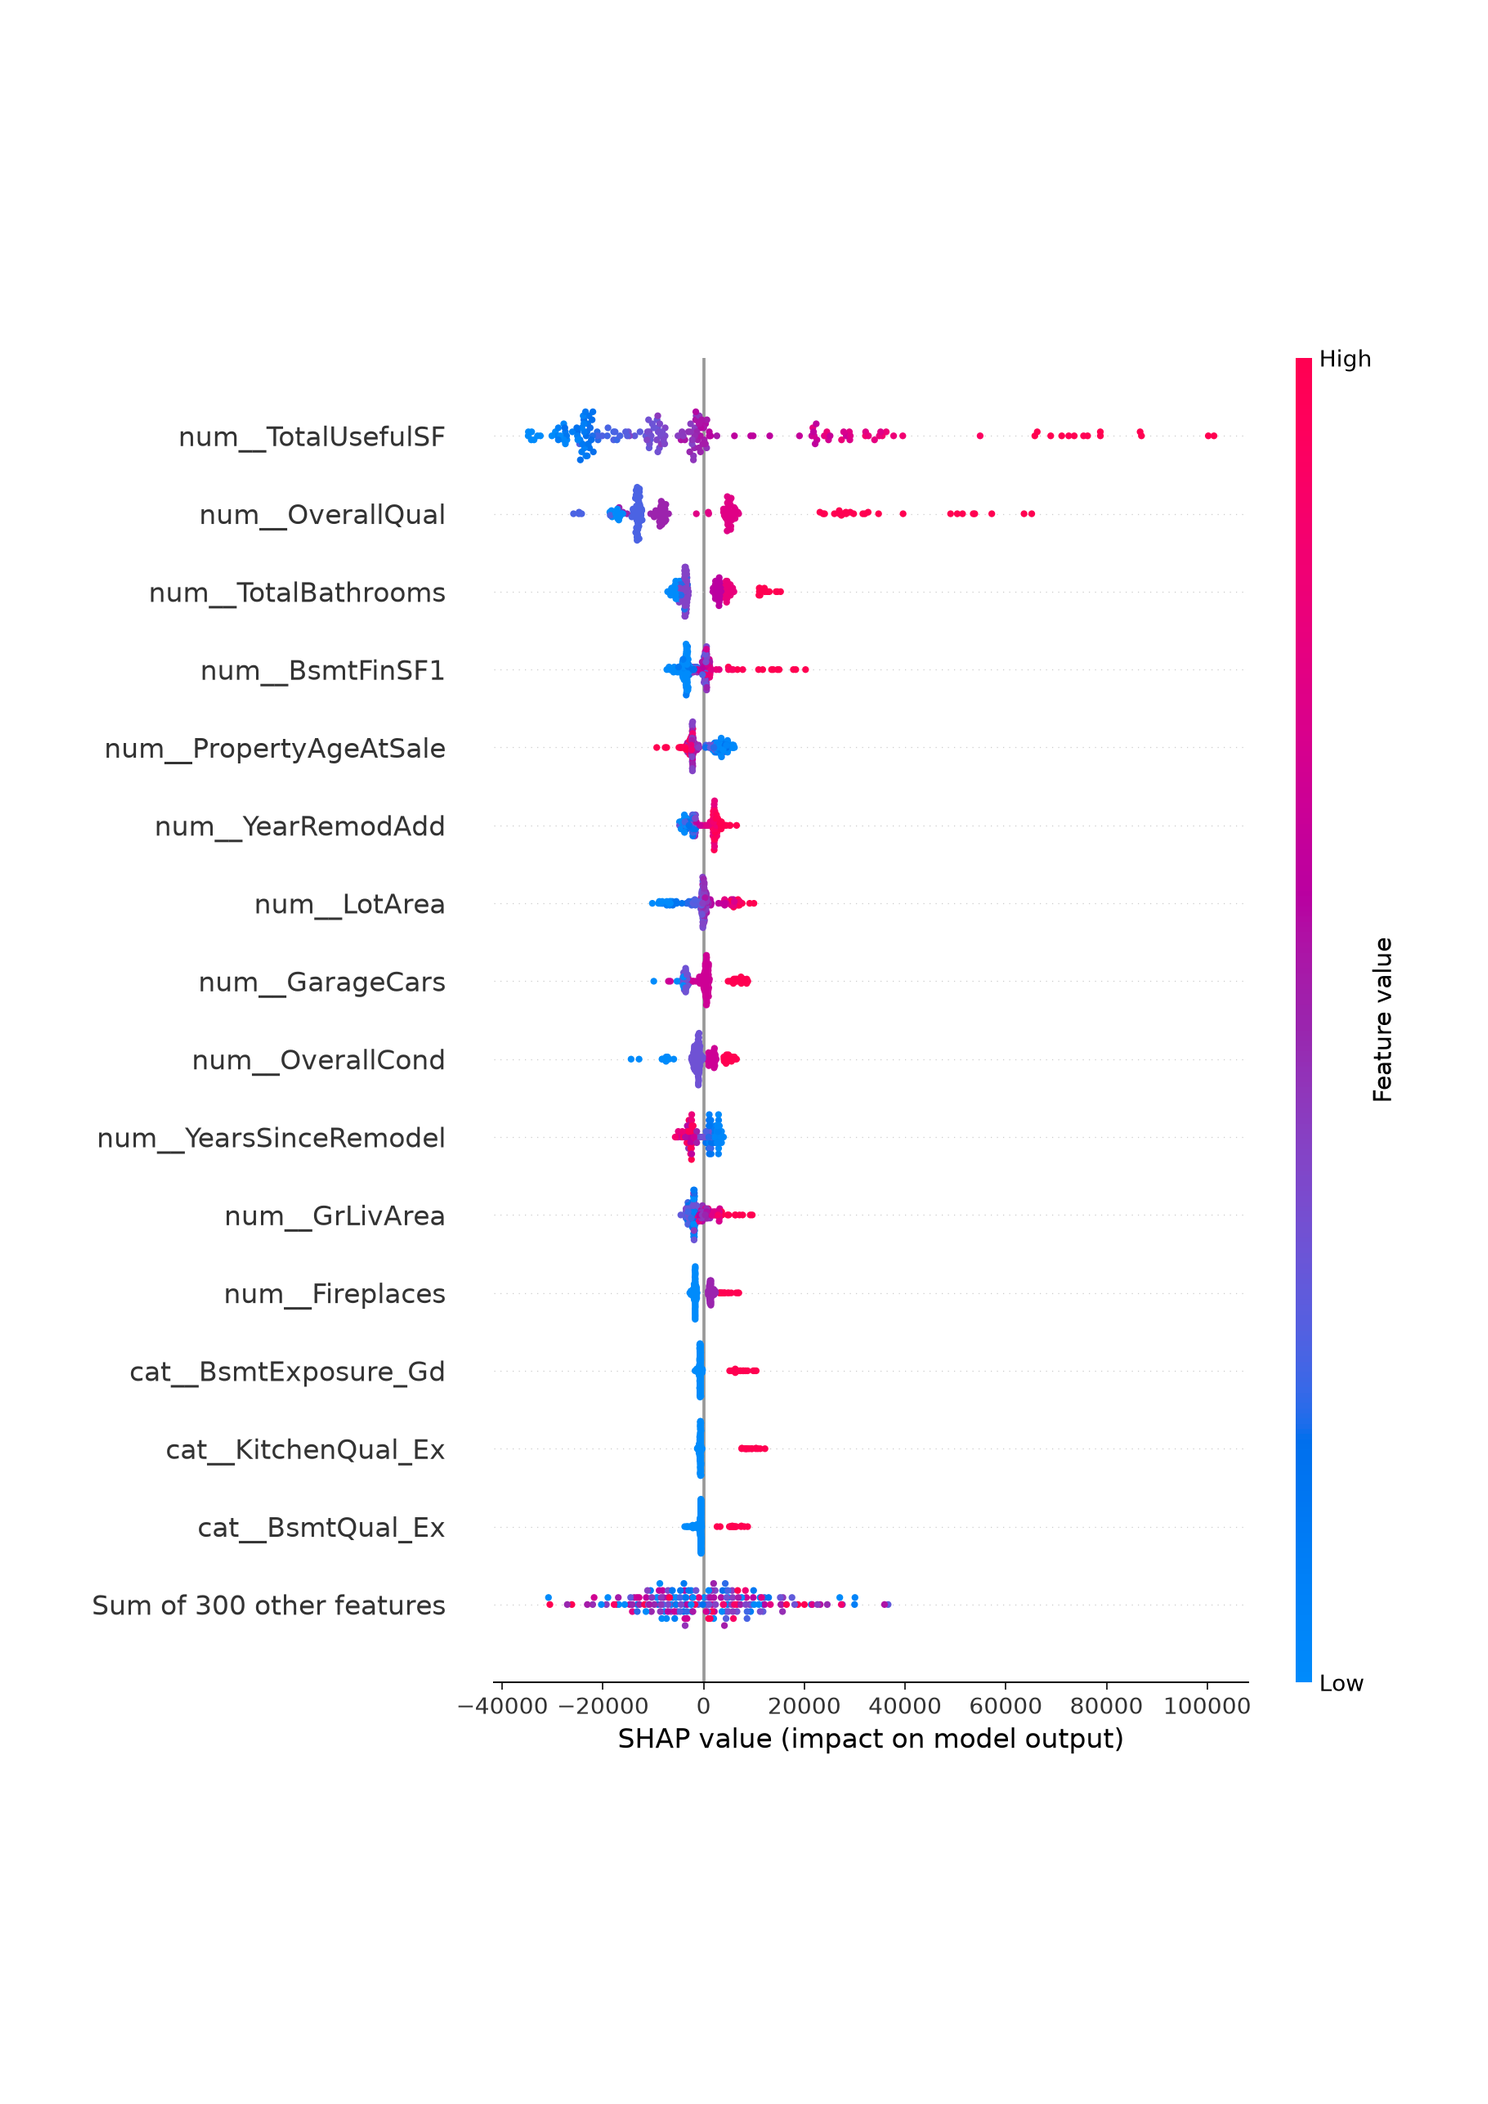

In [6]:
display(Image(filename=str(RESULTS / "figures" / "5_3_shap_beeswarm_regression.png")))

*Рисунок 5.3 — SHAP Summary Plot для прогноза стоимости (диаграмма распределения вкладов).*

Каждая точка соответствует одному дому, положение по горизонтали показывает, насколько соответствующий признак повышает или понижает прогноз в долларах относительно базового уровня. Цвет отражает значение преобразованного признака, а не цену дома. Значения числовых признаков стандартизированы, а категориальные представлены индикаторами One-Hot. Точки справа повышают прогноз, слева — снижают его.

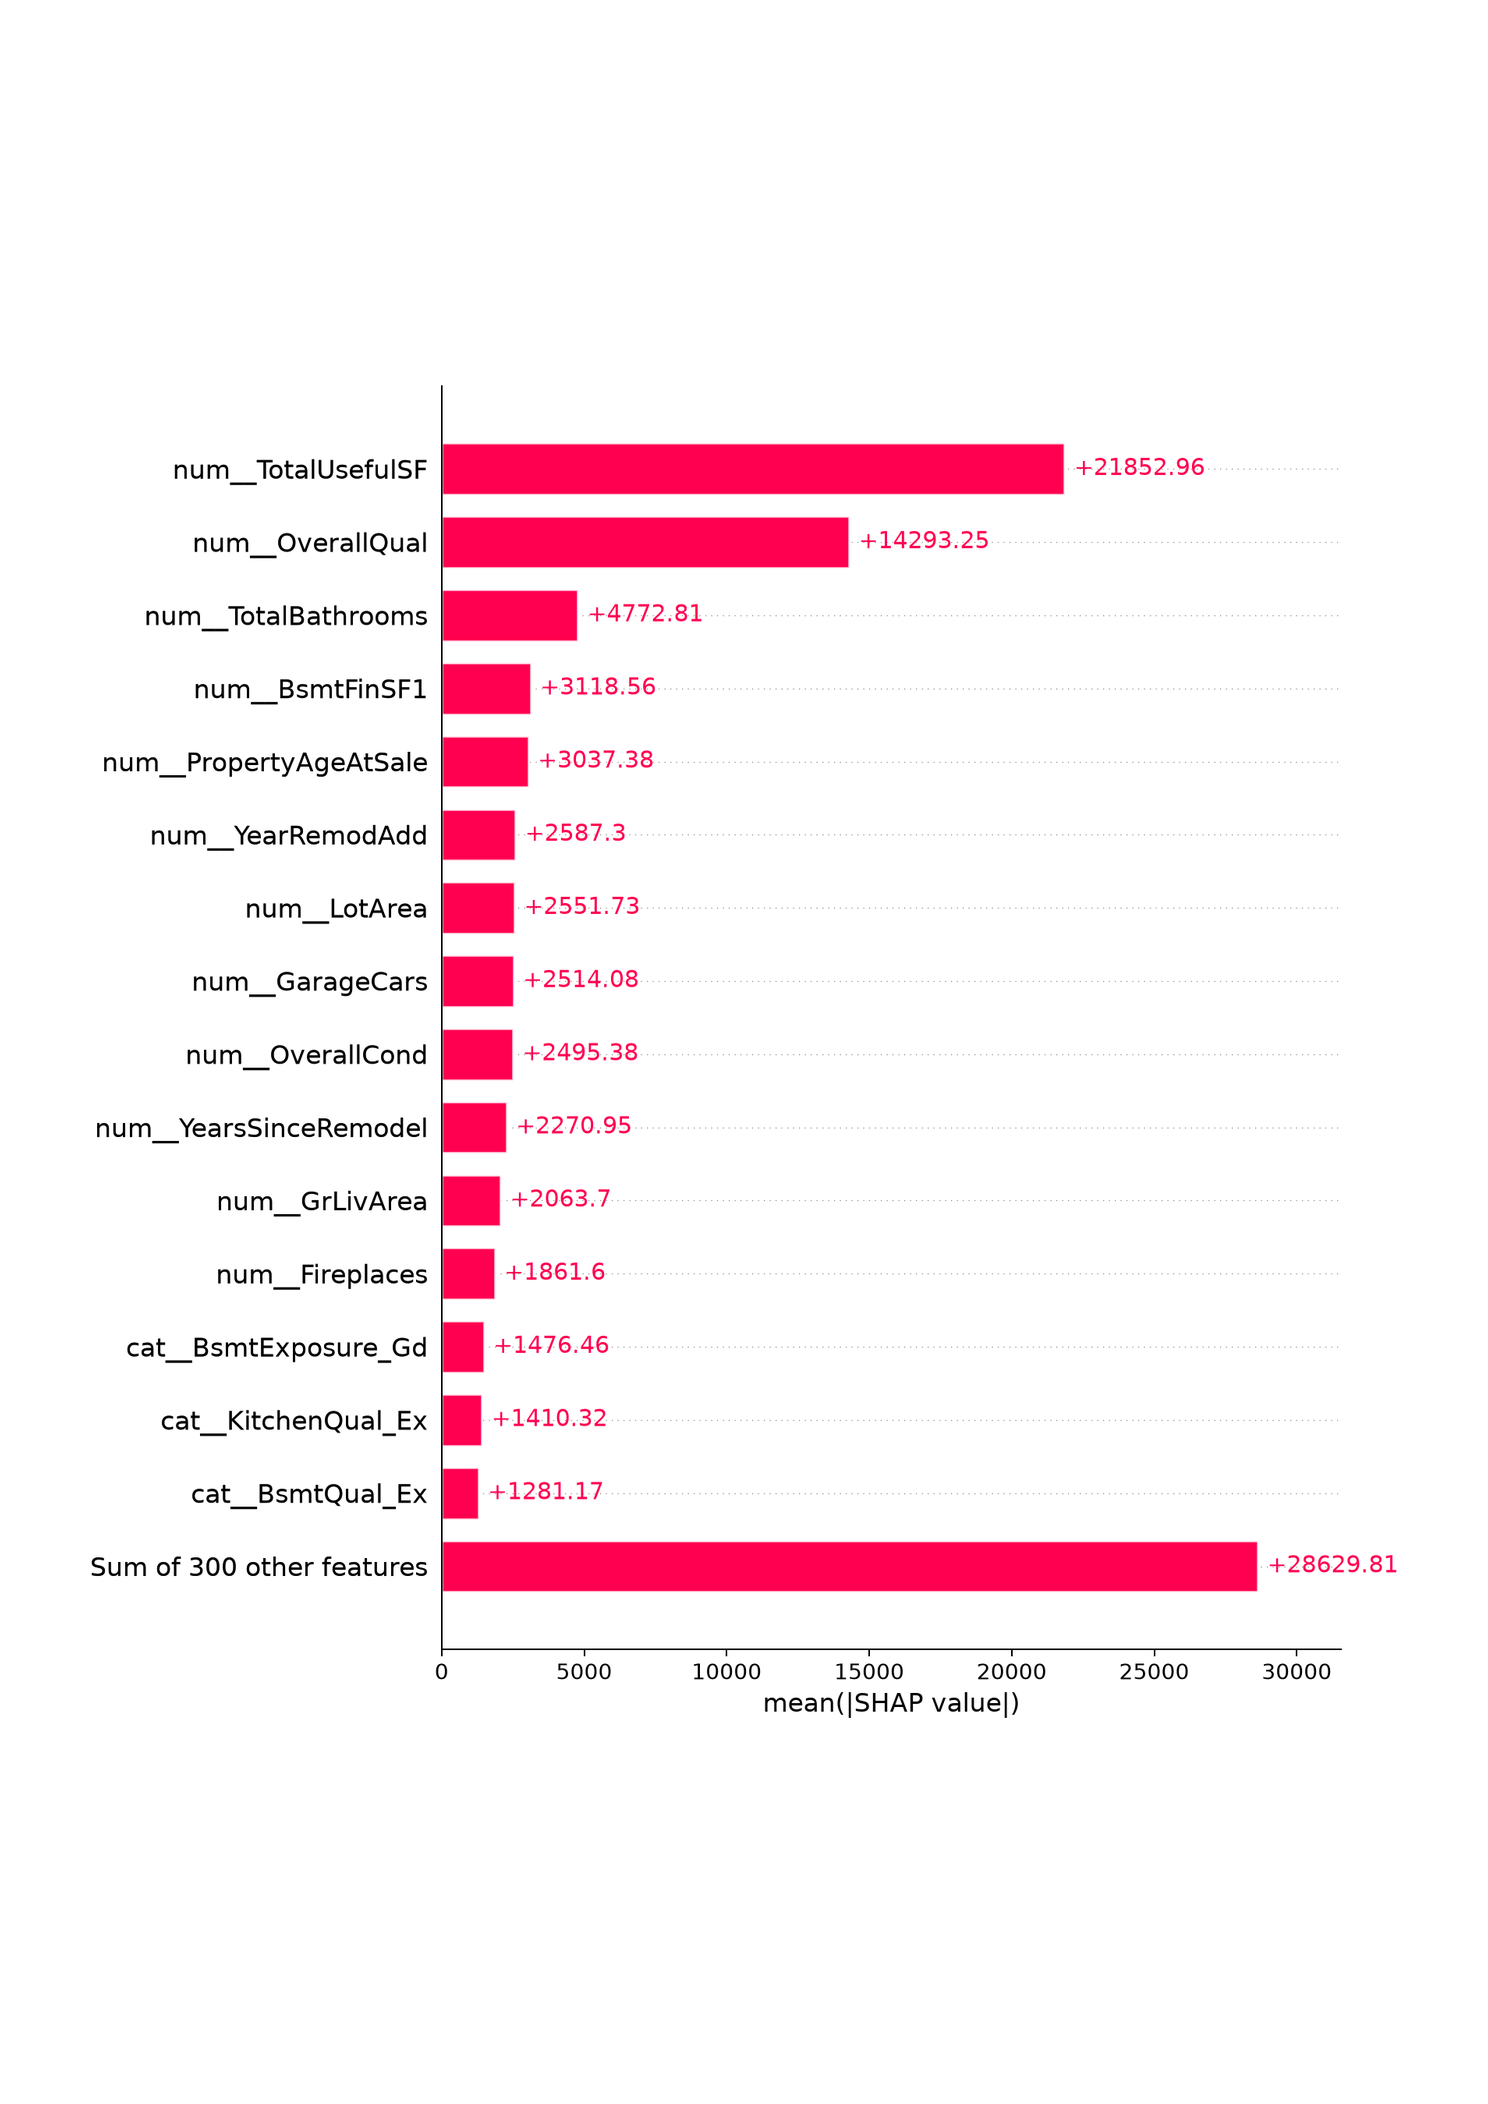

In [7]:
display(Image(filename=str(RESULTS / "figures" / "5_4_shap_bar_regression.png")))

*Рисунок 5.4 — Средние абсолютные SHAP-вклады признаков в регрессионных прогнозах.*

Диаграмма показывает среднюю величину влияния характеристик **без учёта знака**. Поэтому она подходит для ранжирования глобальной важности, но не позволяет сказать, увеличивает ли признак цену. Вместе с рисунком 5.3 она позволяет сопоставить силу и направление вкладов. Результат рассчитан на подвыборке внешнего теста, а не на всех домах исходного набора.

In [8]:
display(pd.read_csv(RESULTS / "shap_global_regression.csv").head(12))

,Feature,MeanAbsSHAP
0,num__TotalUsefulSF,21852.9550
1,num__OverallQual,14293.2540
2,num__TotalBathrooms,4772.8086
3,num__BsmtFinSF1,3118.5570
4,num__PropertyAgeAtSale,3037.3774
5,num__YearRemodAdd,2587.2976
6,num__LotArea,2551.7341
7,num__GarageCars,2514.0780
8,num__OverallCond,2495.3840
9,num__YearsSinceRemodel,2270.9453


## 5. Локальное объяснение стоимости отдельного дома

Id объекта: 1424
Фактическая цена: $274,970.00
Прогноз XGBoost: $160,275.66


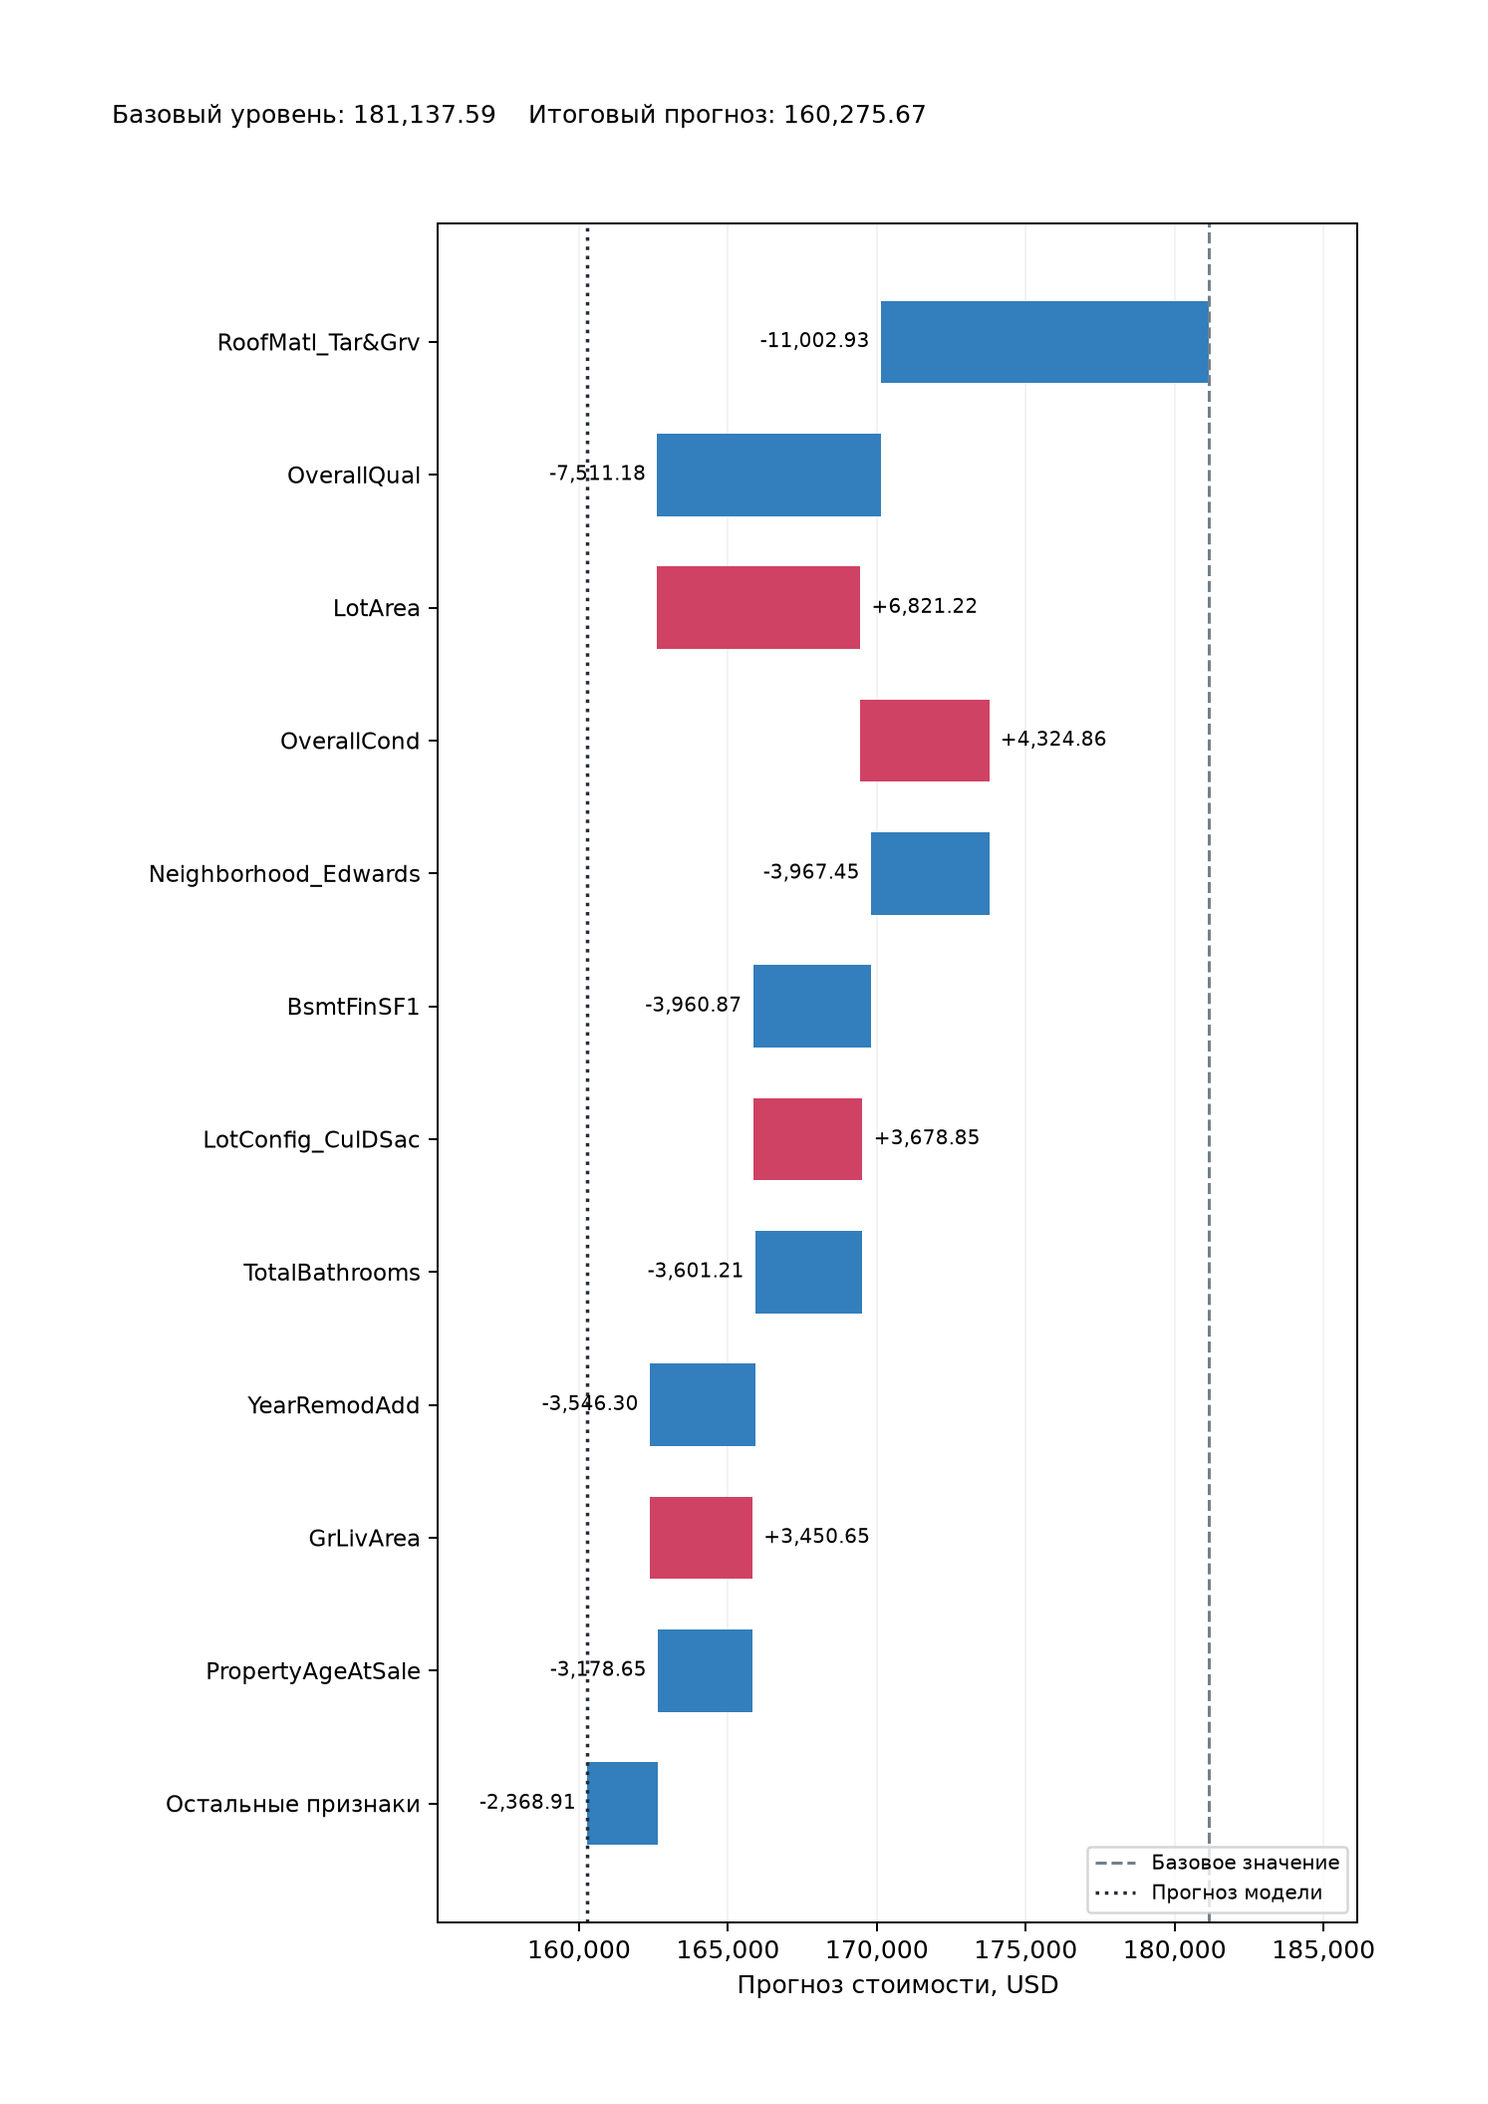

In [9]:
print(f"Id объекта: {local_reg['Id']}")
print(f"Фактическая цена: ${local_reg['Actual']:,.2f}")
print(f"Прогноз XGBoost: ${local_reg['Pred_USD']:,.2f}")
display(Image(filename=str(RESULTS / "figures" / "5_5_shap_waterfall_regression.png")))

*Рисунок 5.5 — Разложение прогноза отдельного дома по SHAP (Waterfall Plot, каскадная диаграмма).*

За базовый уровень принимается значение модели, а стрелки и полосы показывают, как отдельные характеристики изменили итоговый прогноз. Сумма всех вкладов и базового значения точно восстанавливает прогноз XGBoost. Для выбранного дома отдельно полезно сопоставить категорию качества бассейна с фактическим использованием этого признака моделью: нулевой вклад не означает, что наличие бассейна не влияет на рыночную стоимость вообще.

In [10]:
display(pd.read_csv(RESULTS / "local_regression.csv").head(12))
show_force_plot_button("force_regression.html", "Force Plot — стоимость")

,Feature,FeatureValueScaled,SHAP
0,cat__RoofMatl_Tar&Grv,1.000000,-11002.9300
1,num__OverallQual,-0.074699,-7511.1810
2,num__LotArea,2.253476,6821.2220
3,num__OverallCond,1.245799,4324.8620
4,cat__Neighborhood_Edwards,1.000000,-3967.4463
5,num__BsmtFinSF1,-0.963901,-3960.8696
6,cat__LotConfig_CulDSac,1.000000,3678.8486
7,num__TotalBathrooms,-0.269307,-3601.2114
8,num__YearRemodAdd,-0.925245,-3546.3050
9,num__GrLivArea,1.436324,3450.6482


## 6. Глобальный SHAP-анализ ценового сегмента

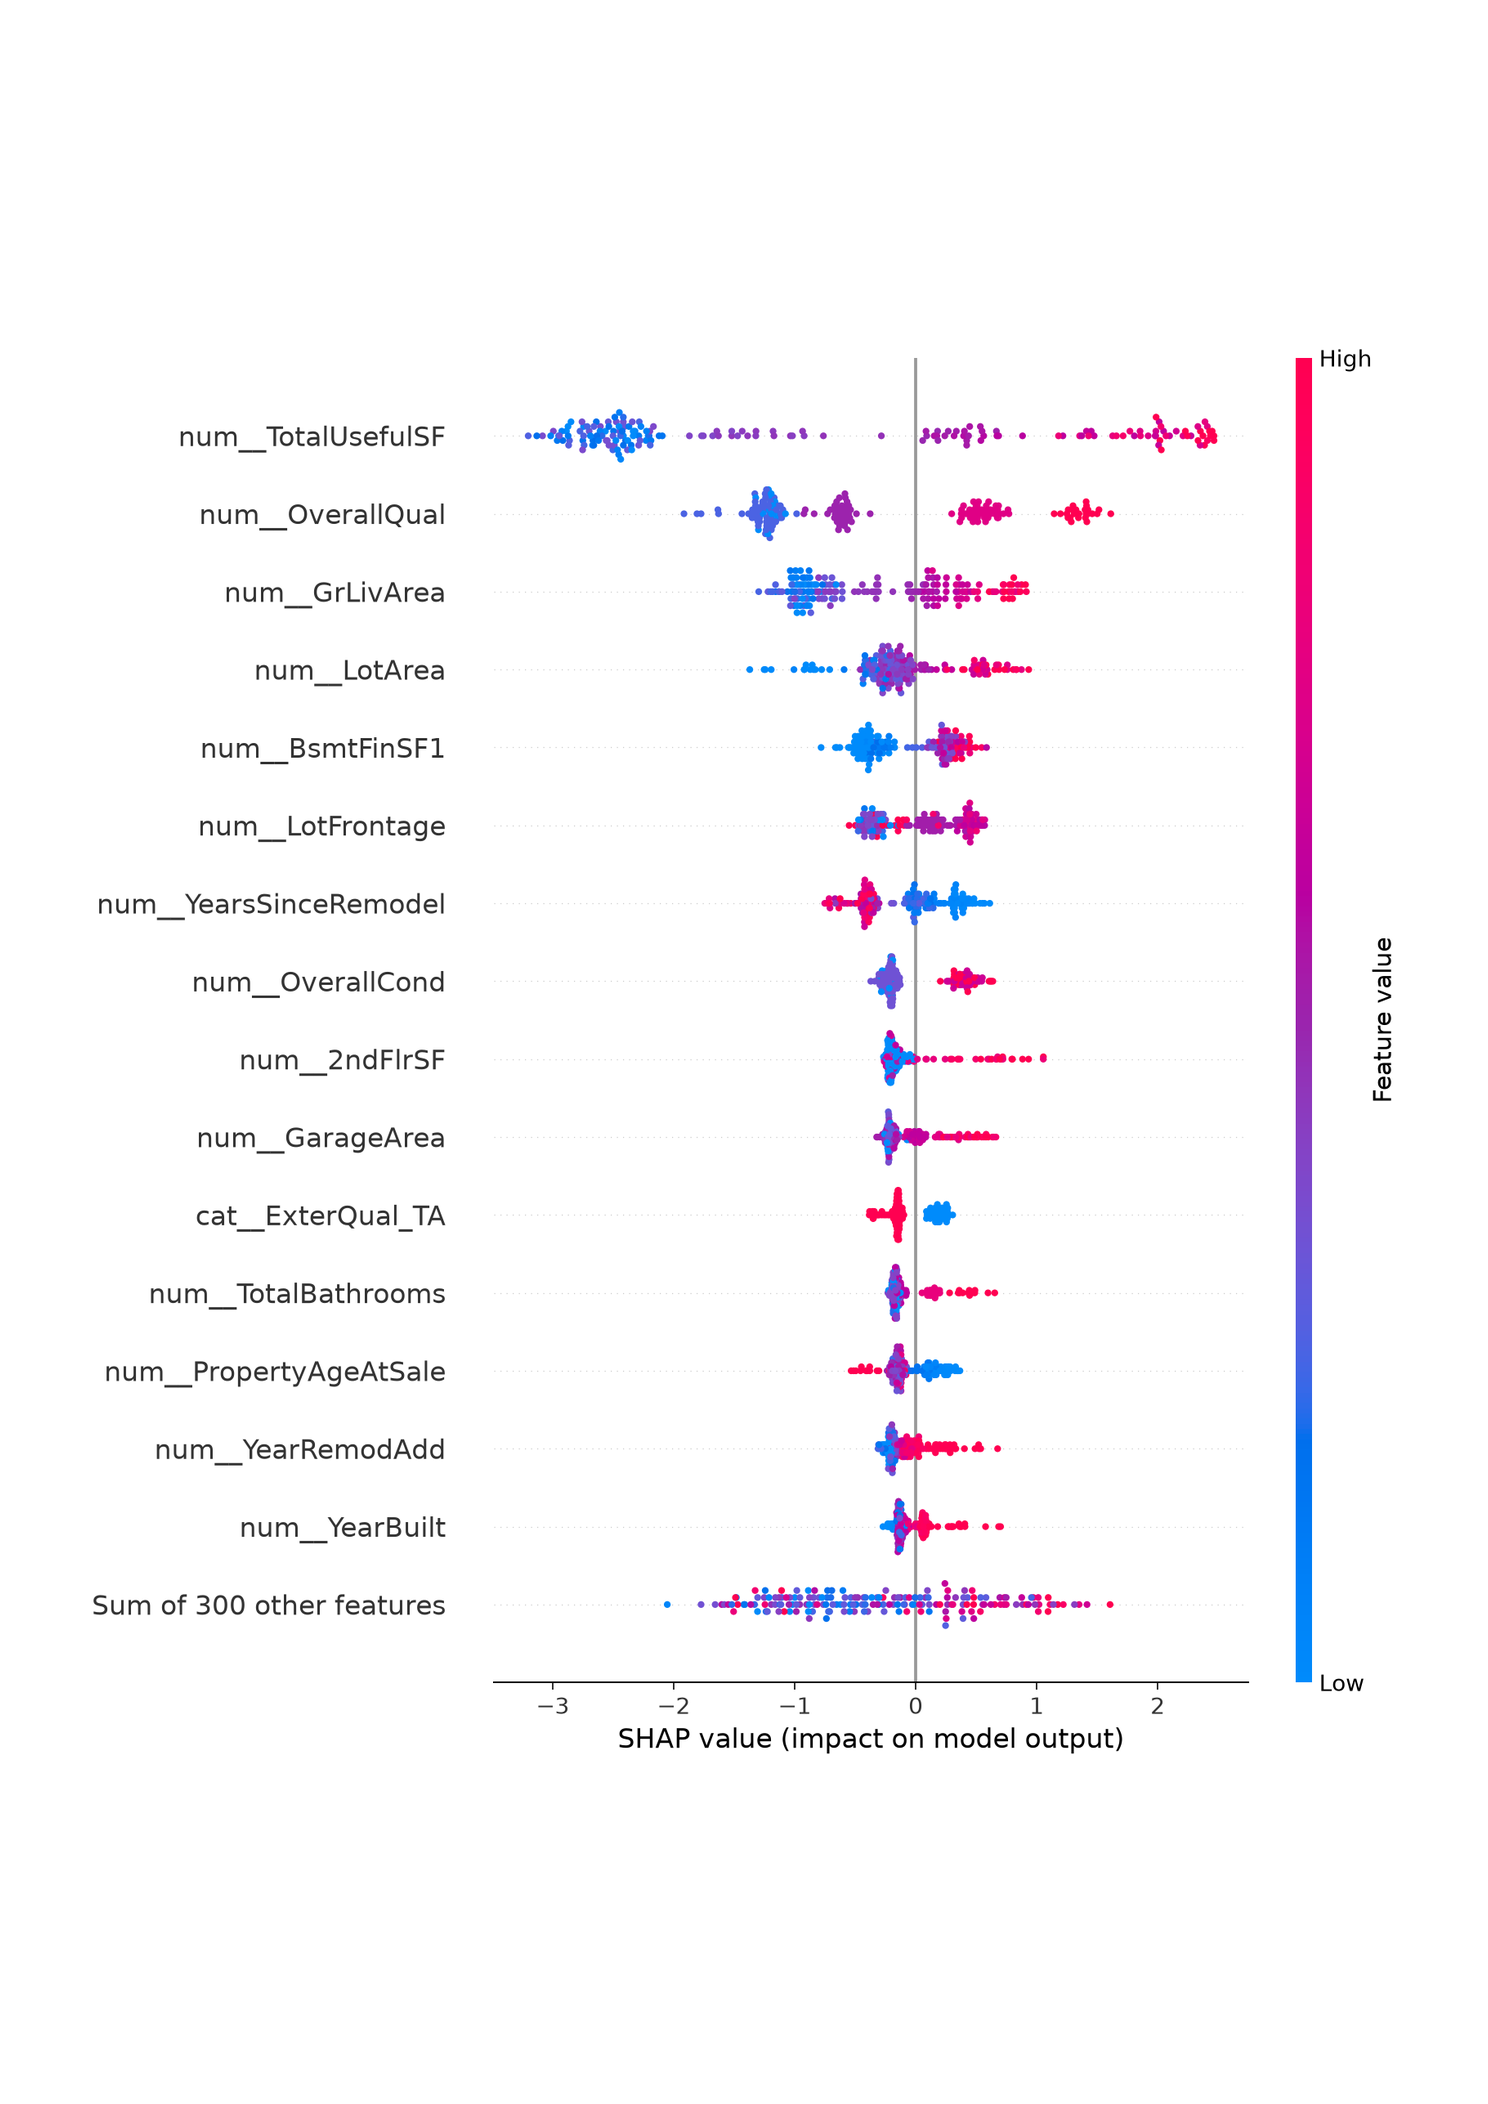

In [11]:
display(Image(filename=str(RESULTS / "figures" / "5_6_shap_beeswarm_classification.png")))

*Рисунок 5.6 — SHAP Summary Plot для классификации ценового сегмента.*

Положительные SHAP-вклады увеличивают **логарифм отношения шансов** принадлежности дому к дорогому сегменту, отрицательные — уменьшают его. Их нельзя читать как изменение вероятности в процентных пунктах. Цвет точек отражает значения признаков после предобработки. Изменение вероятности зависит также от базового значения и остальных вкладов.

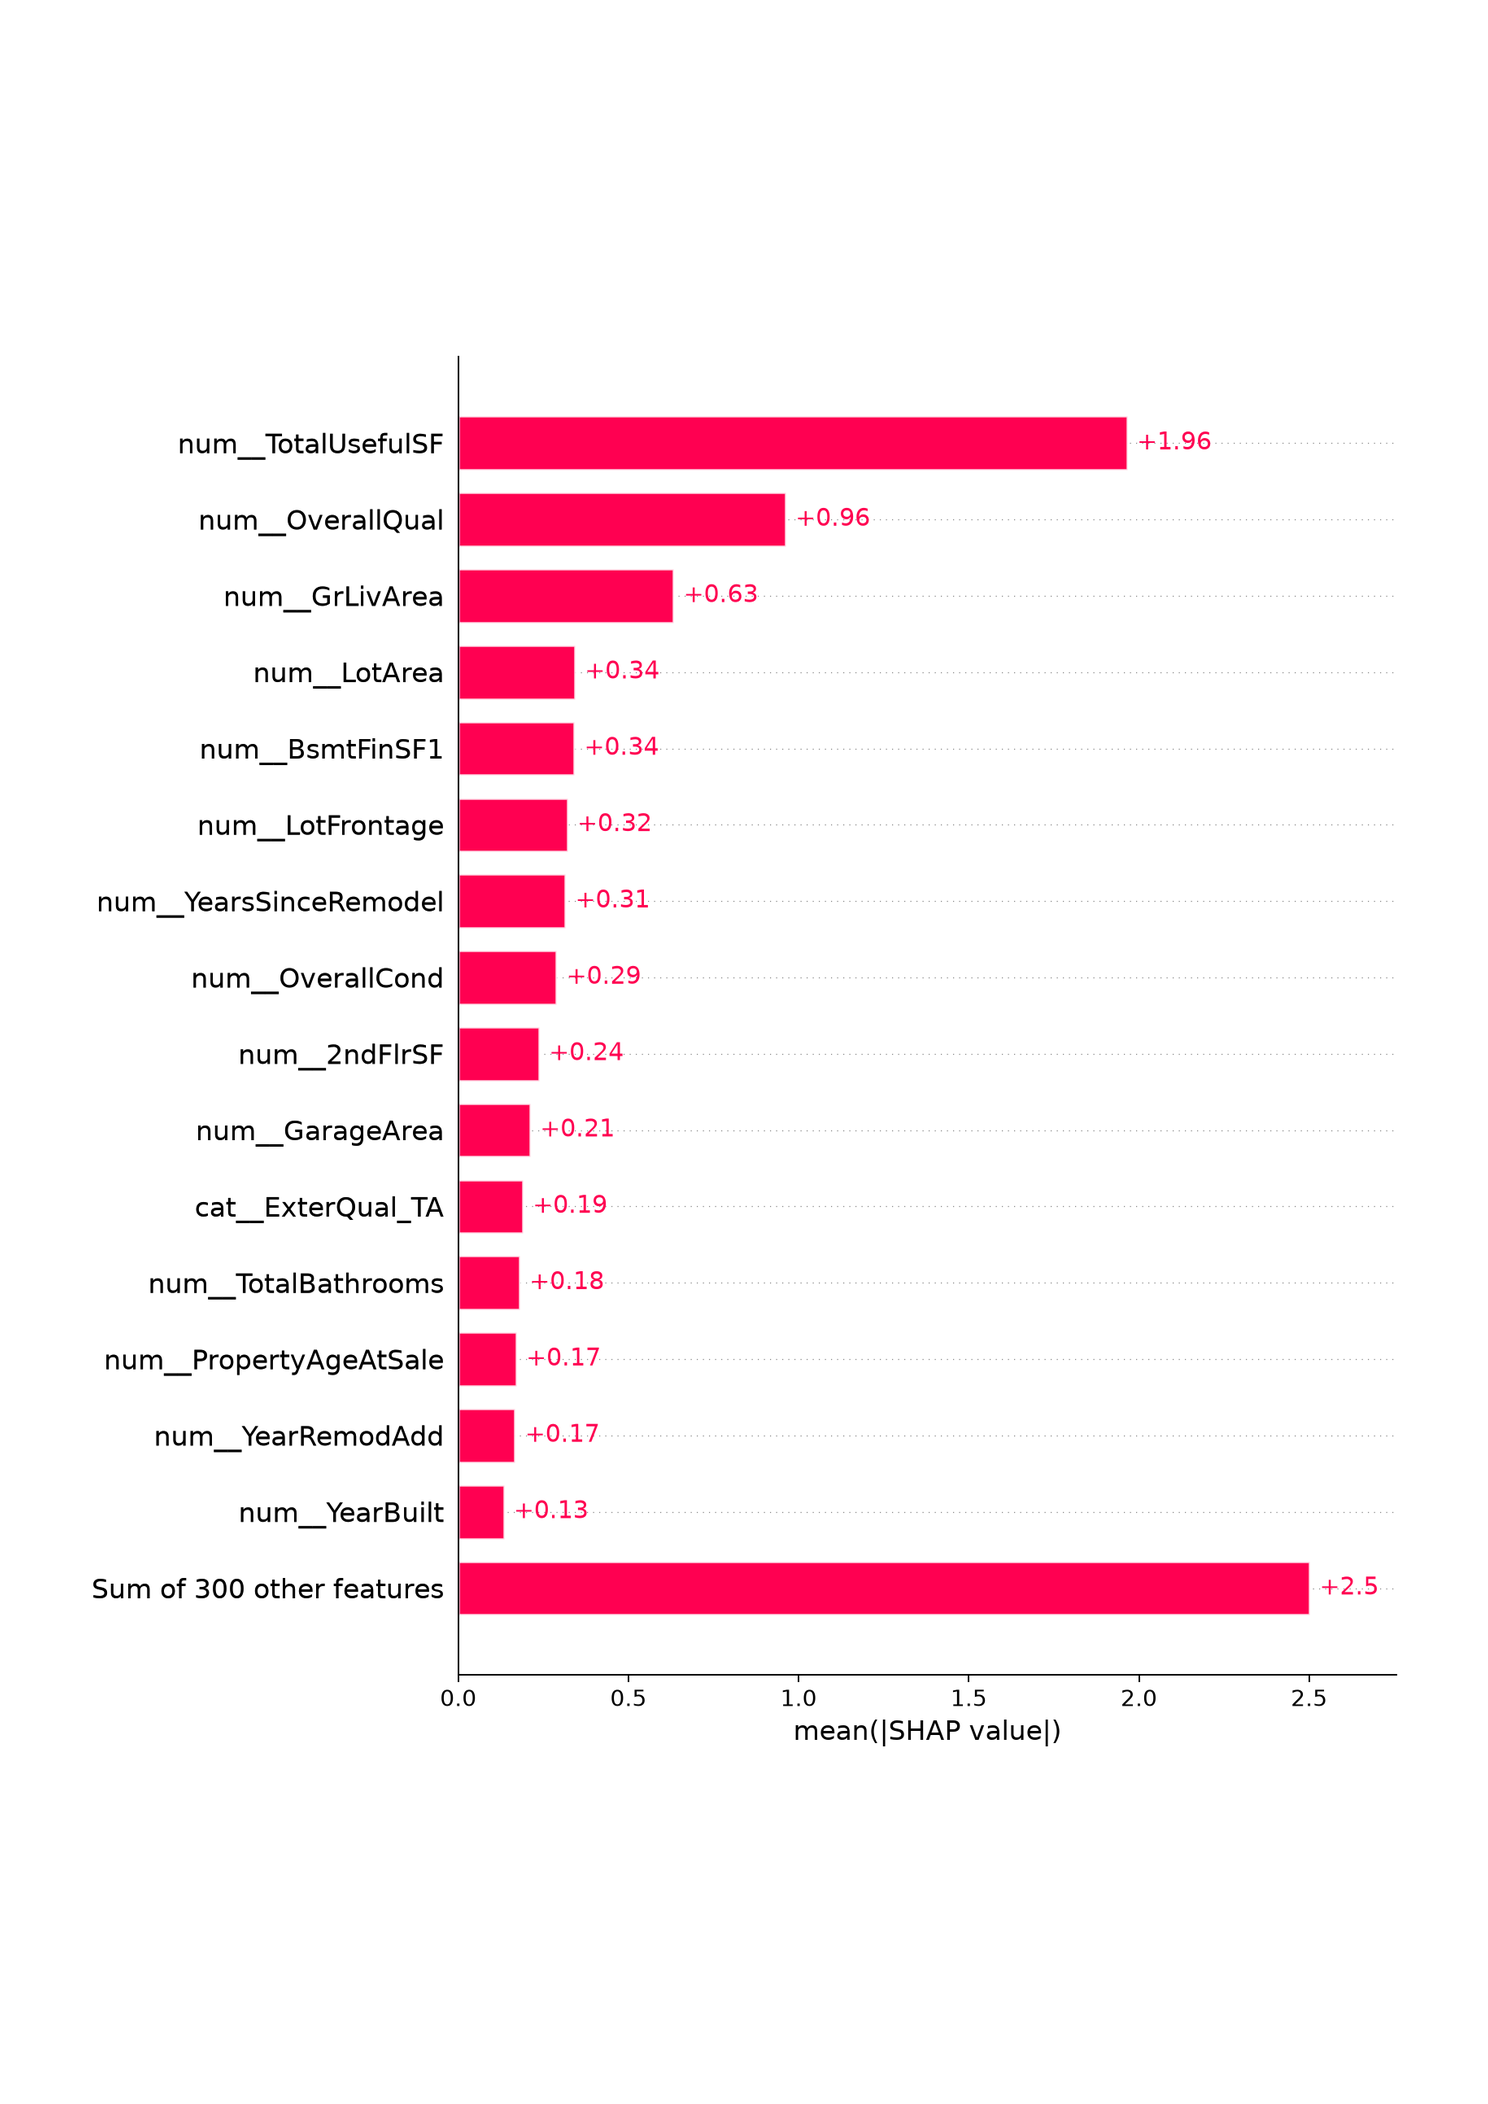

In [12]:
display(Image(filename=str(RESULTS / "figures" / "5_7_shap_bar_classification.png")))

*Рисунок 5.7 — Средние абсолютные SHAP-вклады признаков при определении ценового сегмента.*

Рисунок отражает среднюю величину вкладов на логарифмической шкале шансов без учёта их направления. Он позволяет сравнить характеристики по значимости в рамках классификатора XGBoost. Сопоставление рисунков 5.6 и 5.7 выявляет как общую важность, так и разницу между высокими и низкими значениями признаков.

In [13]:
display(pd.read_csv(RESULTS / "shap_global_classification.csv").head(12))

,Feature,MeanAbsSHAP
0,num__TotalUsefulSF,1.964509
1,num__OverallQual,0.961142
2,num__GrLivArea,0.632224
3,num__LotArea,0.342200
4,num__BsmtFinSF1,0.340364
5,num__LotFrontage,0.319953
6,num__YearsSinceRemodel,0.314180
7,num__OverallCond,0.288079
8,num__2ndFlrSF,0.236957
9,num__GarageArea,0.210709


## 7. Локальное объяснение принадлежности к ценовому сегменту

Id объекта: 1051
Фактический класс: 0
Вероятность класса 1: 52.1%


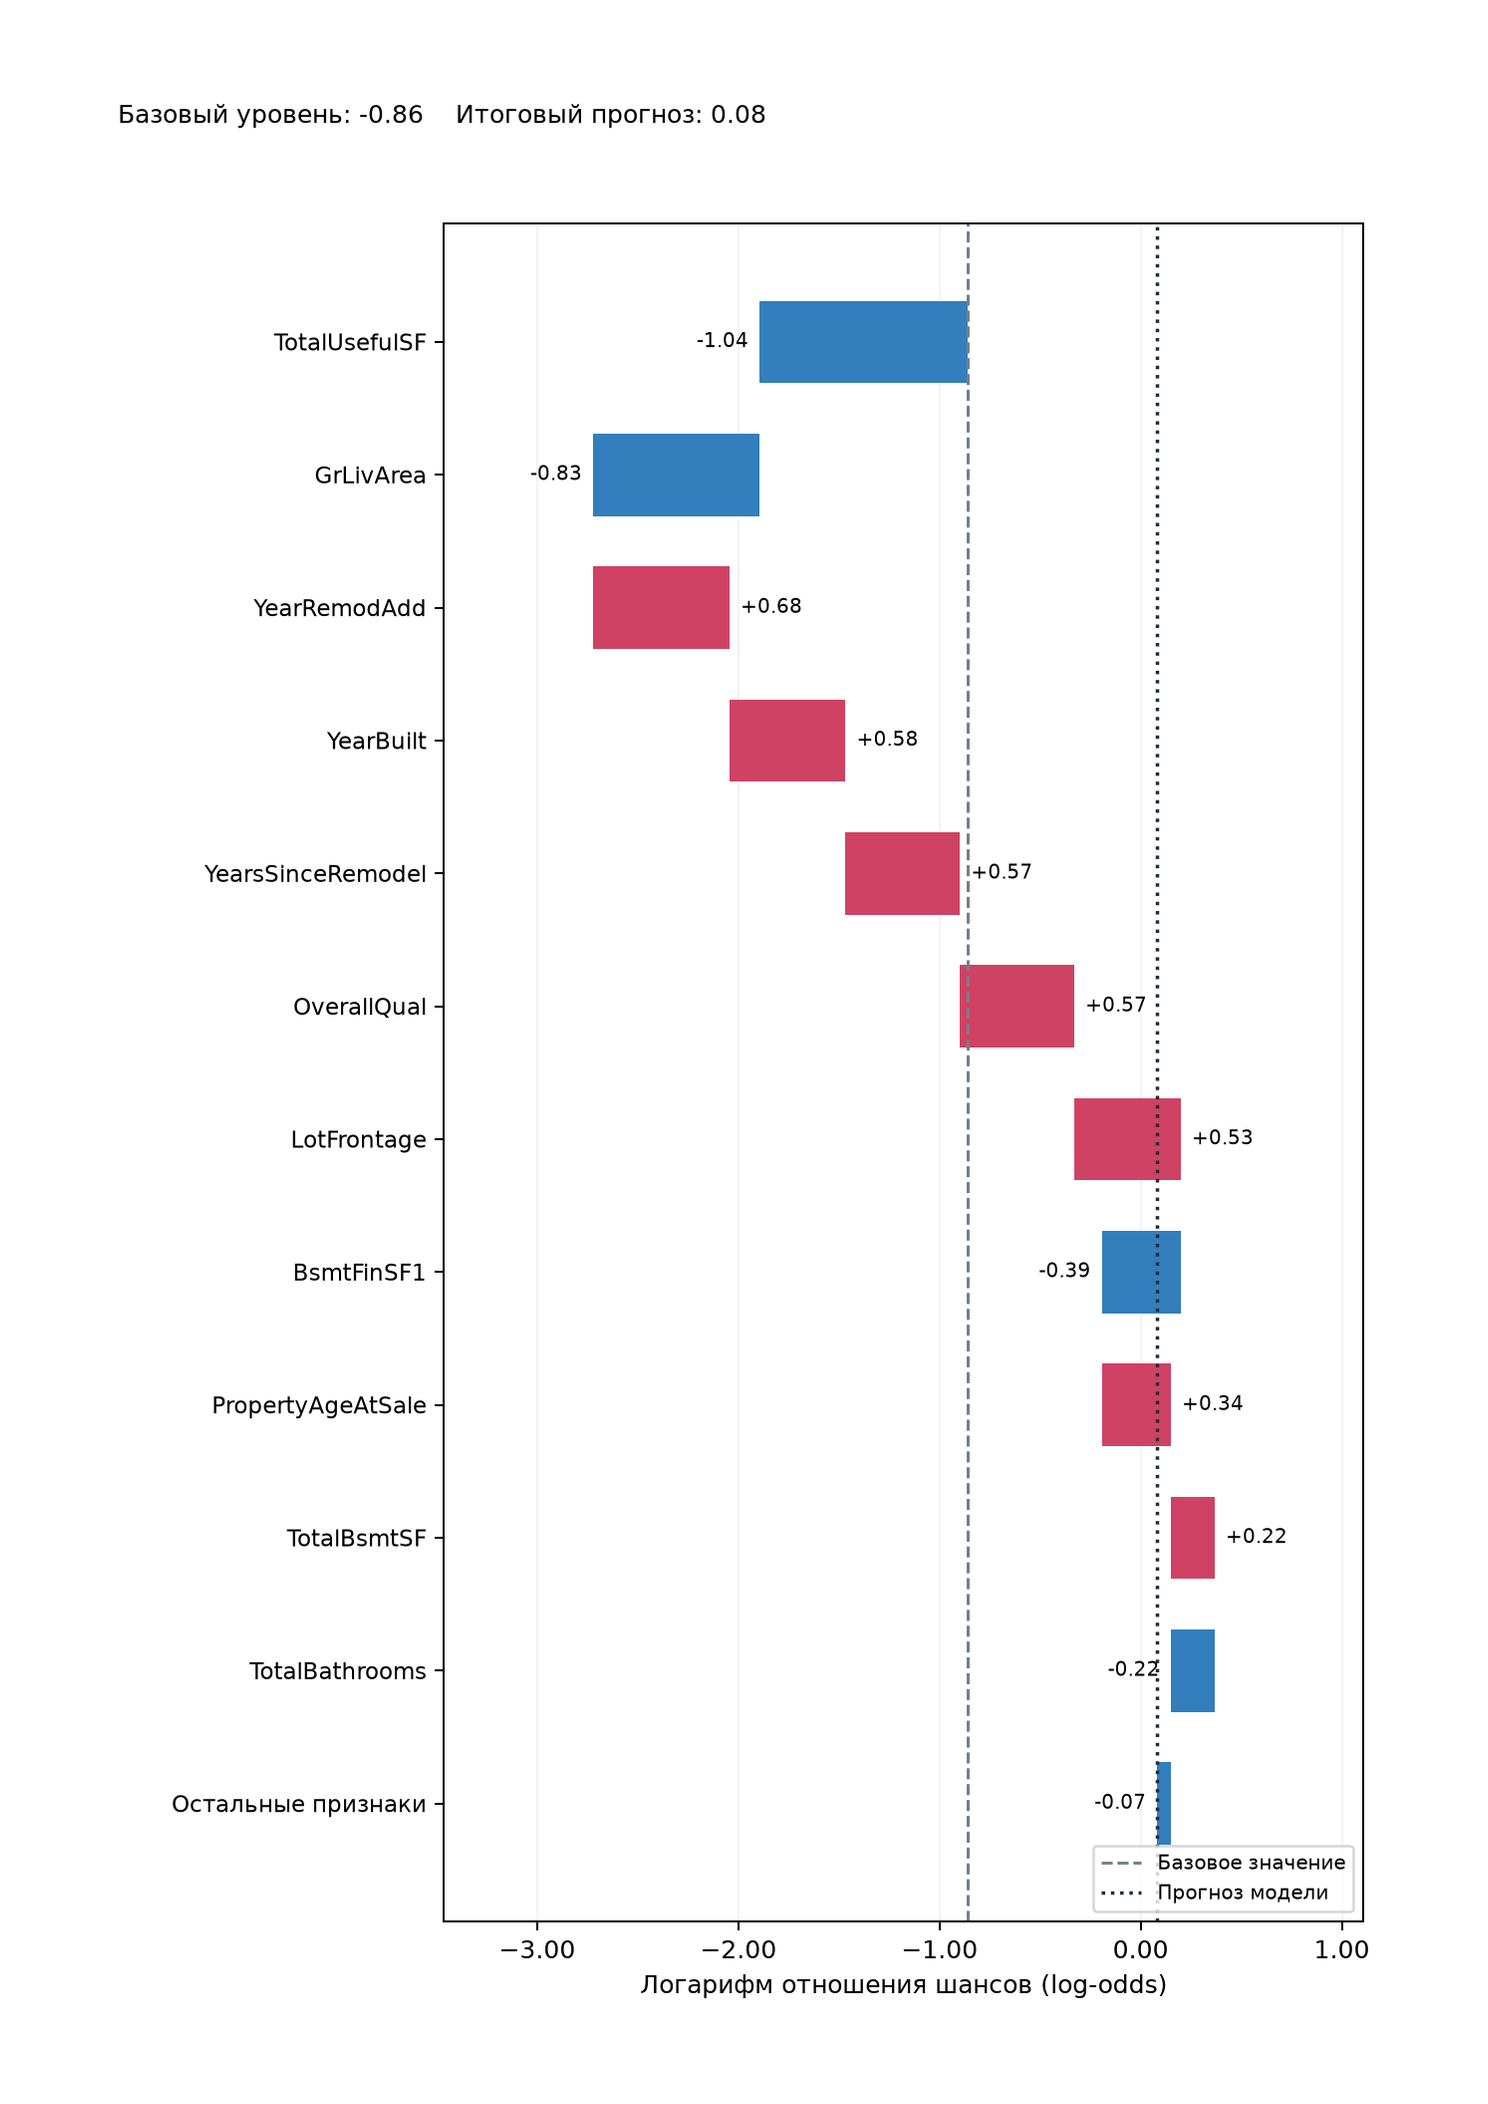

In [14]:
print(f"Id объекта: {local_clf['Id']}")
print(f"Фактический класс: {local_clf['Actual']}")
print(f"Вероятность класса 1: {local_clf['ProbabilityClass1']:.1%}")
display(Image(filename=str(RESULTS / "figures" / "5_8_shap_waterfall_classification.png")))

*Рисунок 5.8 — Разложение классификационного прогноза XGBoost по SHAP.*

Каждый признак добавляет вклад к базовому значению на шкале log-odds (логарифма отношения шансов). Суммарное значение преобразуется логистической функцией в итоговую вероятность принадлежности объекта к классу `1`. В диаграмме допускаются как положительные, так и отрицательные вклады, однако они отражают **работу модели**, а не причинное изменение цены объекта.

In [15]:
display(pd.read_csv(RESULTS / "local_classification.csv").head(12))
show_force_plot_button("force_classification.html", "Force Plot — классификация")

,Feature,FeatureValueScaled,SHAP
0,num__TotalUsefulSF,0.061602,-1.035633
1,num__GrLivArea,-0.412540,-0.827208
2,num__YearRemodAdd,1.067565,0.676683
3,num__YearBuilt,1.184962,0.577193
4,num__YearsSinceRemodel,-1.109002,0.568604
5,num__OverallQual,0.646362,0.568114
6,num__LotFrontage,0.157045,0.529244
7,num__BsmtFinSF1,-0.963901,-0.391640
8,num__PropertyAgeAtSale,-1.211101,0.342434
9,num__TotalBsmtSF,0.621853,0.217745


## 8. Дополнительное сравнение SHAP для Random Forest и XGBoost

Сравнение средней абсолютной величины SHAP-вкладов разных алгоритмов имеет смысл только для одной задачи, одинаковых объектов и одной шкалы прогноза. Для регрессии обе модели дают значения в долларах. Вычисление этого дополнения не входит в основной запуск и выполняется отдельно с параметром `--compare-rf-shap`.

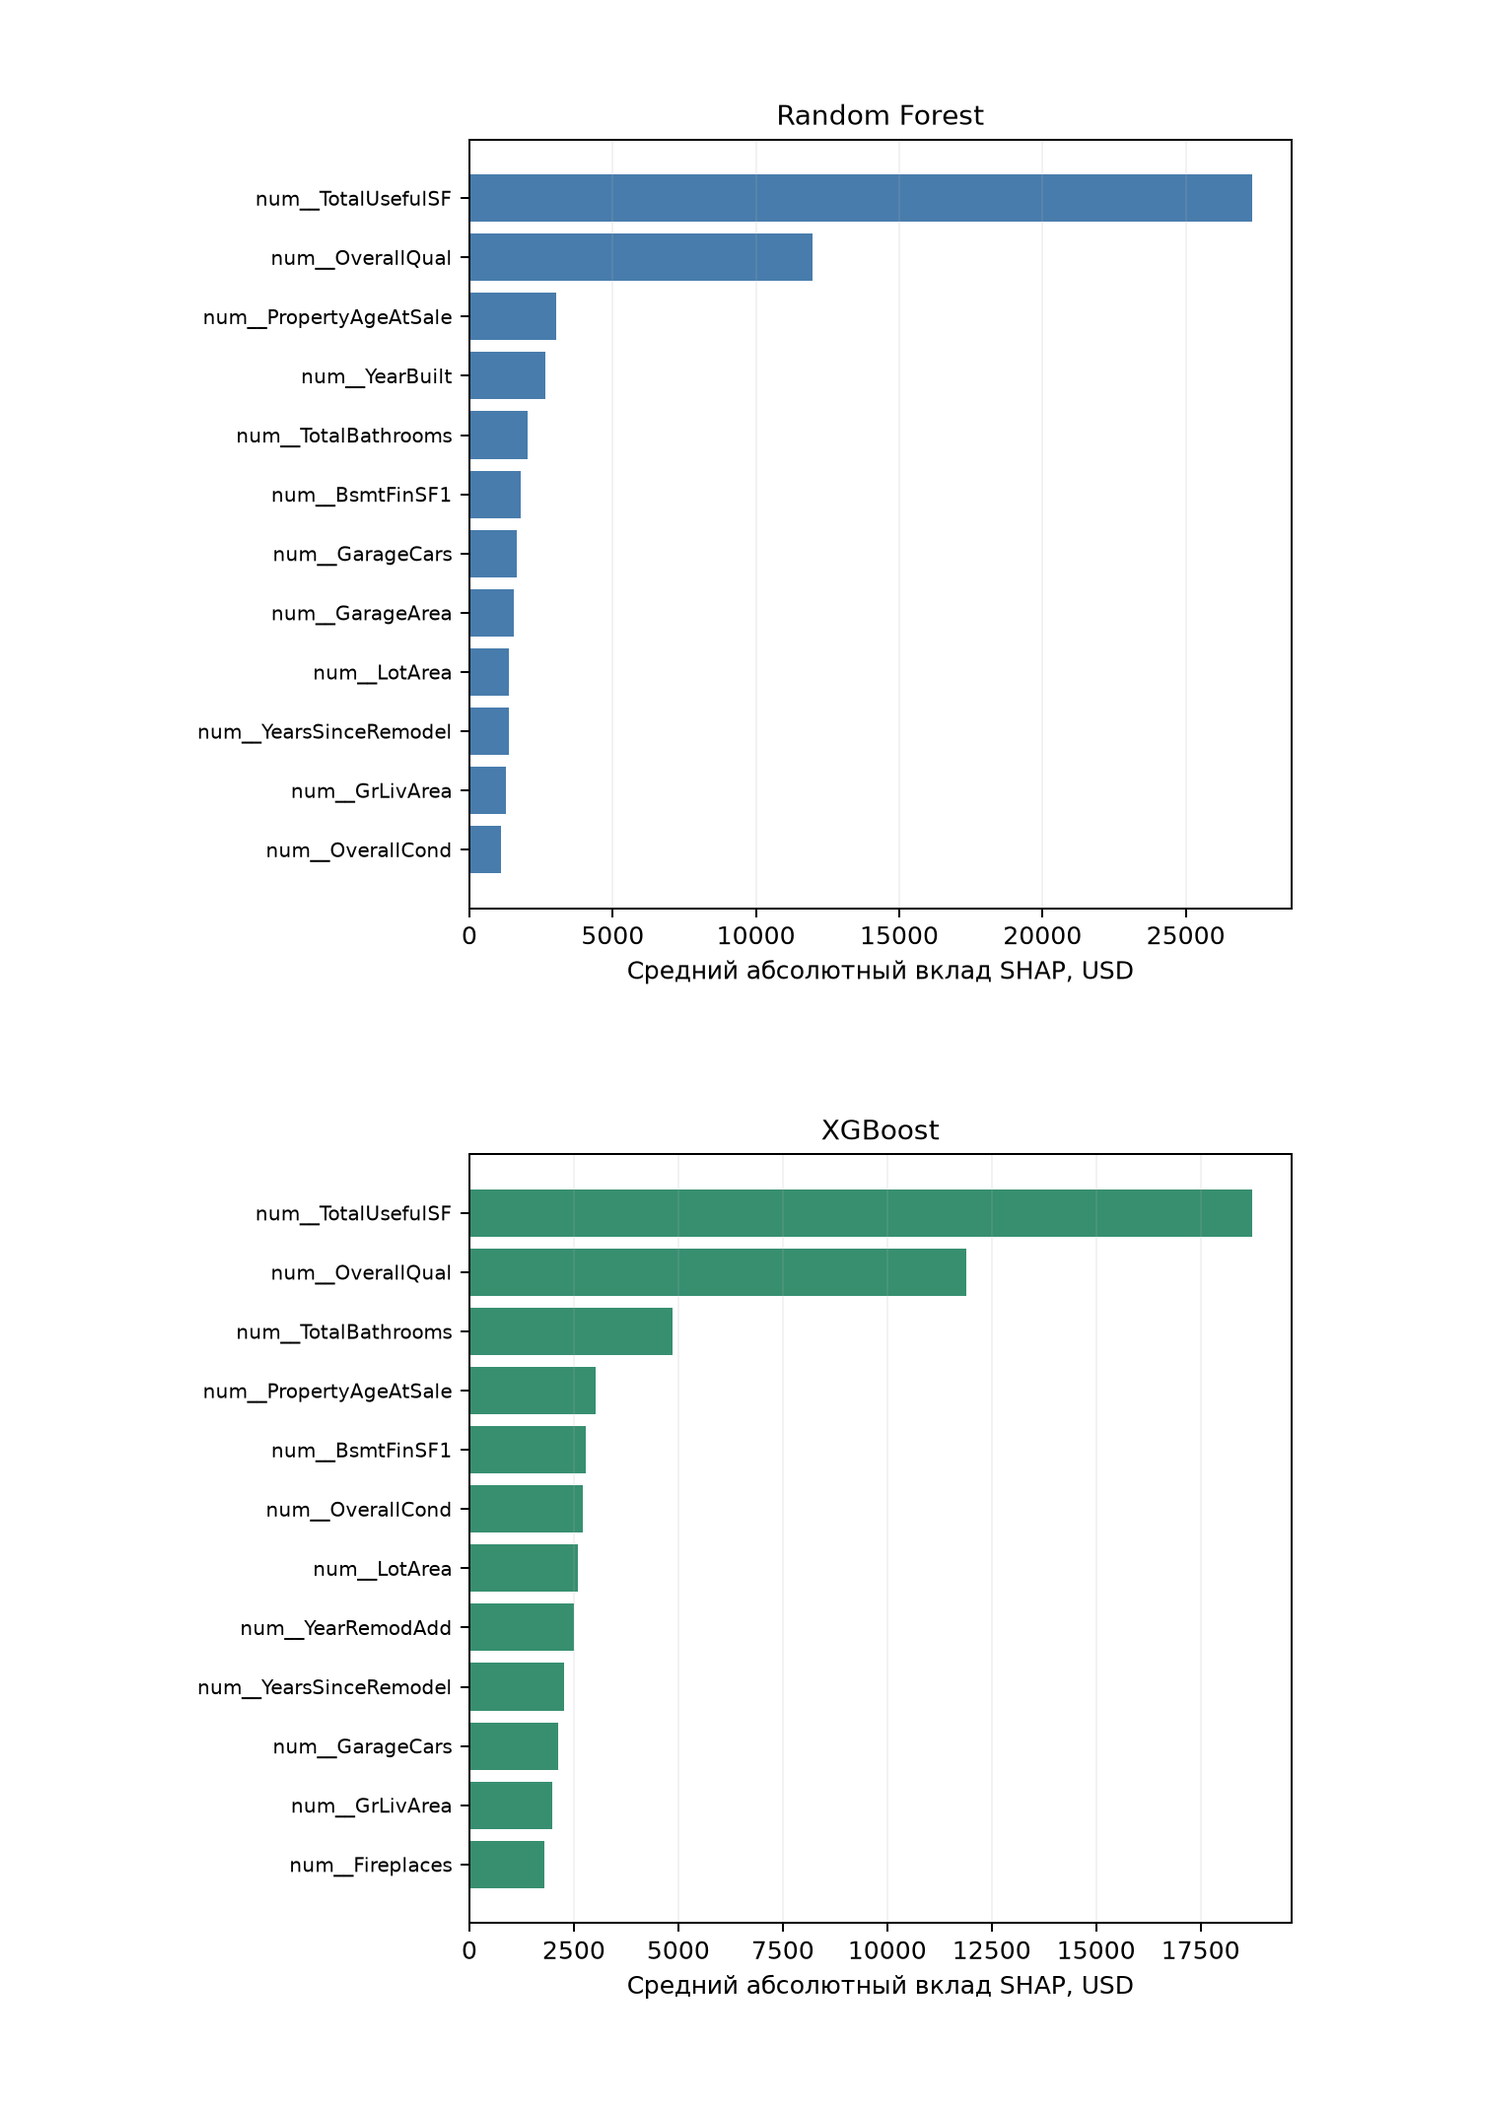

,Feature,RF_MeanAbsSHAP_USD,XGBoost_MeanAbsSHAP_USD
0,num__TotalUsefulSF,27311.592908,18731.2030
1,num__OverallQual,11957.566114,11884.7470
2,num__TotalBathrooms,2045.250349,4861.2720
3,num__PropertyAgeAtSale,3043.745239,3020.1704
4,num__BsmtFinSF1,1791.478547,2787.9014
5,num__OverallCond,1085.736788,2705.6970
6,num__LotArea,1391.211178,2591.1907
7,num__YearRemodAdd,1003.365424,2512.8904
8,num__YearsSinceRemodel,1388.546711,2275.9690
9,num__GarageCars,1636.358449,2124.9429


In [16]:
extra = RESULTS / "figures" / "5_9_shap_rf_xgb_regression.png"
if extra.exists():
    display(Image(filename=str(extra)))
    display(pd.read_csv(RESULTS / "shap_compare_rf_xgb_regression.csv").head(12))
else:
    print("Дополнительный анализ не выполнялся. Команда: python -m house_prices_ai.explainability --compare-rf-shap")

Если рисунок 5.9 построен, он показывает среднюю величину модельных SHAP-вкладов для Random Forest и XGBoost при регрессии. Различия отражают способы использования признаков конкретными моделями, но сами по себе не объясняют различия их точности и не доказывают причинную значимость признаков.

## Итоговые выводы

В исследовании сопоставлена встроенная важность признаков двух ансамблевых алгоритмов — случайного леса и градиентного бустинга XGBoost — для задач прогнозирования стоимости и классификации ценового сегмента. Результаты позволяют сравнить относительные рейтинги характеристик, но не указывают на прямой причинно-следственный эффект признаков.

SHAP-анализ дополнил глобальные показатели локальными объяснениями конкретных прогнозов. Для регрессии вклады интерпретируются в долларах США, для бинарной классификации XGBoost — в логарифме отношения шансов. Во всех исследованных случаях выполнена проверка аддитивности: сумма базового уровня и вкладов воспроизводит исходное предсказание модели.

Отдельное внимание уделено дому с нетипичной характеристикой бассейна и объекту, расположенному около границы классификационного решения. Их интерпретация демонстрирует зависимость прогнозов от конкретных сочетаний признаков, но не используется как независимая проверка качества моделей.

Полученные объяснения ограничены обученными конфигурациями алгоритмов, выборкой объектов для SHAP и зависимостями между признаками. Эти ограничения необходимо учитывать при формулировании предметных выводов и дальнейшем использовании моделей.